# Recommender Systems

Recommender systems suggest items a user is likely to enjoy. This notebook demonstrates the two
classic families:

- **Content-based filtering** - recommend items similar to what a user already likes, using item
  metadata such as genres or descriptions.
- **Collaborative filtering** - use the rating patterns of many users to infer preferences.
  We cover item-item similarity and matrix factorisation with SVD.

## Learning objectives

1. Build a user-item rating matrix.
2. Recommend similar items with content-based cosine similarity.
3. Predict ratings with item-item collaborative filtering.
4. Use truncated SVD for matrix factorisation.
5. Evaluate rating predictions with RMSE and discuss ranking metrics and cold start.

## 1. Concepts

### Content-based filtering

Represent each item by features (genres, tags, text embeddings). Compute similarity between items,
then recommend items closest to the user's liked items.

- Pros: no other users needed; works for new items with metadata.
- Cons: limited to item features; tends to recommend items very similar to past choices.

### Collaborative filtering

Use the user-item rating matrix. Two common approaches:

1. **Neighbourhood methods** - find similar users or items and aggregate their ratings.
2. **Matrix factorisation** - learn low-dimensional user and item factors whose dot product predicts
   a rating.

- Pros: can discover unexpected tastes; no item metadata needed.
- Cons: cold start for new users/items; popularity bias; sparse data.

### Evaluation

- **RMSE / MAE** for rating prediction.
- **Precision@k, recall@k, NDCG** for ranked recommendations.
- Always evaluate on held-out ratings, not on ratings used for training.

## 2. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

## 3. A synthetic movie catalogue and rating matrix

We create 12 movies, 10 users, and a sparse set of ratings. The data is synthetic so the notebook
stays offline and reproducible.

In [2]:
movies = pd.DataFrame({
    "movie_id": range(1, 13),
    "title": [
        "Galaxy Quest", "Star Fall", "Love in Paris", "The Last Letter",
        "Deep Ocean", "City Lights", "Robot Revolution", "The Comedians",
        "Silent Hill", "Summer Road", "Cold Case", "Dream Garden",
    ],
    "genres": [
        "sci-fi comedy space", "sci-fi action space", "romance drama paris",
        "romance drama letters", "documentary ocean nature", "drama romance city",
        "sci-fi action robots", "comedy stand-up", "horror mystery",
        "comedy road trip", "thriller crime mystery", "fantasy drama garden",
    ],
})

rng = np.random.default_rng(RANDOM_STATE)
n_users = 10
rating_rows = []
for user in range(1, n_users + 1):
    for movie_id in movies["movie_id"]:
        if rng.random() < 0.65:
            rating_rows.append({
                "user_id": user,
                "movie_id": movie_id,
                "rating": int(rng.integers(1, 6)),
            })

ratings = pd.DataFrame(rating_rows)
ratings = ratings.merge(movies[["movie_id", "title"]], on="movie_id")
print("Ratings:", len(ratings), "Users:", ratings["user_id"].nunique(), "Movies:", ratings["movie_id"].nunique())
ratings.head()

Ratings: 78 Users: 10 Movies: 12


,user_id,movie_id,rating,title
0,1,2,3,Star Fall
1,1,4,5,The Last Letter
2,1,8,5,The Comedians
3,1,9,3,Silent Hill
4,1,11,3,Cold Case


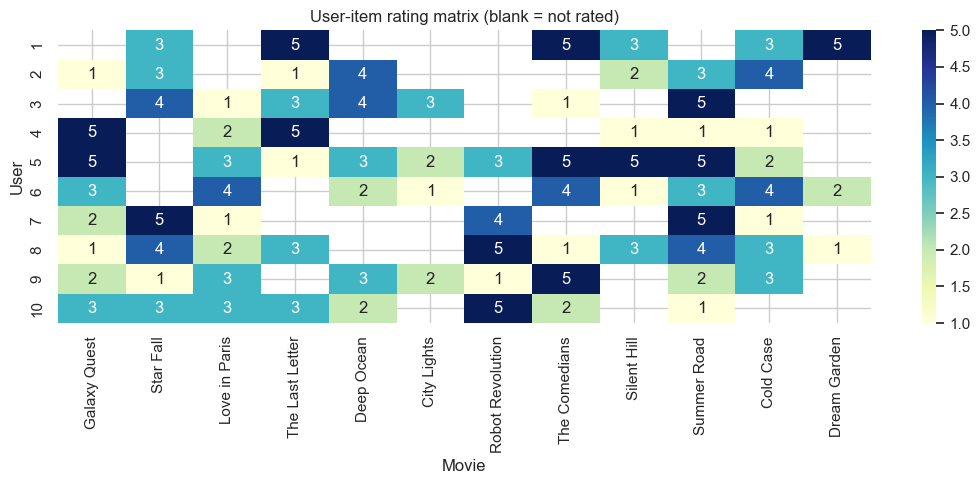

In [3]:
rating_matrix = ratings.pivot(index="user_id", columns="movie_id", values="rating")
rating_matrix.index.name = "user_id"
rating_matrix.columns = [movies.loc[movies["movie_id"] == m, "title"].iloc[0] for m in rating_matrix.columns]

plt.figure(figsize=(11, 5))
sns.heatmap(rating_matrix, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("User-item rating matrix (blank = not rated)")
plt.xlabel("Movie")
plt.ylabel("User")
plt.tight_layout()
plt.show()

## 4. Content-based recommendations

We convert genres to TF-IDF vectors and compute cosine similarity between movies. The function below
recommends the movies most similar to a given title.

In [4]:
tfidf = TfidfVectorizer()
genre_matrix = tfidf.fit_transform(movies["genres"])
content_similarity = cosine_similarity(genre_matrix)

content_sim_df = pd.DataFrame(
    content_similarity,
    index=movies["title"],
    columns=movies["title"],
)

def recommend_similar(title, n=5):
    scores = content_sim_df[title].drop(title).sort_values(ascending=False)
    return scores.head(n).round(3)

recommend_similar("Star Fall")

title
Galaxy Quest        0.742
Robot Revolution    0.686
Love in Paris       0.000
The Last Letter     0.000
Deep Ocean          0.000
Name: Star Fall, dtype: float64

## 5. Collaborative filtering with item-item similarity

We compute cosine similarity between item rating vectors and predict a user's rating for an item as
a similarity-weighted average of the user's other ratings.

In [5]:
train_ratings, test_ratings = train_test_split(
    ratings, test_size=0.2, random_state=RANDOM_STATE
)

train_matrix = train_ratings.pivot(index="user_id", columns="movie_id", values="rating")
train_matrix = train_matrix.reindex(index=range(1, n_users + 1), columns=movies["movie_id"])

# Cosine similarity treats missing values as zero, which is the usual neighbourhood baseline.
filled = train_matrix.fillna(0)
item_similarity = cosine_similarity(filled.T)
item_similarity_df = pd.DataFrame(
    item_similarity,
    index=movies["movie_id"],
    columns=movies["movie_id"],
)

def predict_item_item(user_id, movie_id):
    user_ratings = train_matrix.loc[user_id]
    similarities = item_similarity_df[movie_id]
    mask = user_ratings.notna() & (similarities > 0)
    if not mask.any():
        return train_matrix.loc[user_id].mean()
    weights = similarities[mask]
    return float(np.dot(weights, user_ratings[mask]) / weights.sum())

item_predictions = []
for row in test_ratings.itertuples():
    item_predictions.append(predict_item_item(row.user_id, row.movie_id))

item_rmse = np.sqrt(np.mean((test_ratings["rating"].to_numpy() - np.array(item_predictions)) ** 2))
print("Item-item RMSE:", round(item_rmse, 4))

Item-item RMSE: 1.5984


## 6. Matrix factorisation with truncated SVD

We fill missing ratings with each user's mean, centre the matrix, and factorise it. The reconstructed
matrix gives predictions for unrated movies.

In [6]:
user_means = train_matrix.mean(axis=1)
centered = train_matrix.sub(user_means, axis=0)
centered_filled = centered.fillna(0)

svd = TruncatedSVD(n_components=3, random_state=RANDOM_STATE)
user_factors = svd.fit_transform(centered_filled)
item_factors = svd.components_

reconstructed = np.dot(user_factors, item_factors)
reconstructed = pd.DataFrame(
    reconstructed,
    index=train_matrix.index,
    columns=train_matrix.columns,
).add(user_means, axis=0)

svd_predictions = [
    reconstructed.loc[row.user_id, row.movie_id]
    for row in test_ratings.itertuples()
]
svd_rmse = np.sqrt(np.mean((test_ratings["rating"].to_numpy() - np.array(svd_predictions)) ** 2))
print("SVD RMSE:", round(svd_rmse, 4))
print("Explained variance ratio:", np.round(svd.explained_variance_ratio_, 3))

SVD RMSE: 1.6112
Explained variance ratio: [0.425 0.171 0.143]


In [7]:
def recommend_for_user(user_id, n=5):
    seen = train_matrix.loc[user_id].dropna().index
    scores = reconstructed.loc[user_id].drop(index=seen, errors="ignore").sort_values(ascending=False)
    titles = [movies.loc[movies["movie_id"] == m, "title"].iloc[0] for m in scores.index[:n]]
    return pd.DataFrame({"movie_id": scores.index[:n], "title": titles, "predicted_rating": scores.values[:n]}).round(3)

print("Top recommendations for user 1:")
recommend_for_user(1)

Top recommendations for user 1:


,movie_id,title,predicted_rating
0,1,Galaxy Quest,4.788
1,3,Love in Paris,4.718
2,11,Cold Case,4.534
3,6,City Lights,4.455
4,5,Deep Ocean,4.405


## 7. Evaluation beyond RMSE

RMSE measures rating accuracy, but users experience a ranked list. Ranking metrics include:

- **Precision@k**: fraction of the top-k recommendations that are relevant.
- **Recall@k**: fraction of relevant items that appear in the top-k.
- **NDCG@k**: discounted gain that rewards relevant items near the top.

To compute them you need a definition of relevance (for example, rating >= 4) and a held-out set of
positive interactions.

## 8. Cold start and bias

- **New user**: no ratings -> cannot personalise. Use popularity, content preferences, or onboarding.
- **New item**: no ratings -> content-based similarity can help.
- **Popularity bias**: popular items dominate recommendations, reducing discovery.
- **Feedback loops**: recommendations change user behaviour and future training data.
- **Privacy**: ratings can be sensitive; collect and store only what is needed.

## Key takeaways

- Content-based filtering uses item features; collaborative filtering uses collective behaviour.
- Item-item similarity and SVD are simple, explainable baselines.
- Always hold out ratings for evaluation.
- RMSE is not the whole story; ranking metrics and business outcomes matter.
- Cold start, popularity bias, and privacy are first-class design concerns.

## Exercises

1. Compare user-user and item-item collaborative filtering.
2. Tune the number of SVD components and plot RMSE vs `n_components`.
3. Implement Precision@5 using ratings >= 4 as relevant.
4. Add a popularity baseline (recommend the highest average rating with a minimum count).
5. Explain how a new movie with no ratings could still be recommended with content-based filtering.